In [1]:
%pip install pandas gensim tensorflow tensorflow[and-cuda] scikit-learn matplotlib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# arreglo para poder importar evaluate_model sin que de error
from pathlib import Path
import sys

for project_root in (Path.cwd(), *Path.cwd().parents):
    if (project_root / "evaluation" / "metrics.py").is_file():
        sys.path.insert(0, str(project_root))
        break
else:
    raise FileNotFoundError("No se encontró evaluation/metrics.py en los directorios superiores.")

from evaluation.metrics import evaluate_model

zsh:1: no matches found: tensorflow[and-cuda]
Note: you may need to restart the kernel to use updated packages.


# Clasificador Bag of Words (BoW) con Regresión Logística

En este notebook implementamos un clasificador de sentimientos basado en **Bag of Words (BoW)** con `CountVectorizer` y un modelo de **Regresión Logística**,

# Carga Inicial de Datos

[Sentiment140](https://huggingface.co/datasets/stanfordnlp/sentiment140) es un conjunto de datos de gran escala para la clasificación del sentimiento en Twitter, que contiene 1,6 millones de tuits etiquetados automáticamente mediante emoticonos como forma de supervisión distante (*distant supervision*).

Los tuits que contienen emoticonos positivos (p. ej., :), :-)) se etiquetan como positivos (`sentiment=4`), mientras que los que contienen emoticonos negativos (p. ej., :(, :-() se etiquetan como negativos (`sentiment=0`). Este conjunto de datos se utiliza ampliamente como referencia para la clasificación de sentimientos binaria y multiclase en la investigación sobre procesamiento del lenguaje natural (PLN).



In [2]:
import io, zipfile, urllib.request
import re, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers

_URL = "http://help.sentiment140.com/home"
_DATA_URL = "https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip"

_TRAIN_FILE_NAME = "training.1600000.processed.noemoticon.csv"

# Descargamos el zip con el Dataset
with urllib.request.urlopen(_DATA_URL) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    
cols = ["target", "id", "date", "flag", "user", "text"]
df = pd.read_csv(zf.open(_TRAIN_FILE_NAME), encoding="latin-1", header=None, names=cols)
df = df[["target", "text"]].copy() # solo quiero esas dos columnas
df["label"] = (df["target"] == 4).astype(int)  # cambiar el 4 por un 1 -> 0 = negativo, 1 = positivo


# Pre-processing

Partimos de texto generalmente muy informal con abreviaciones, faltas de ortografia, #, @ de usuarios y un monton de palabras y abreviaciones polisemicas.

Por lo que si queremos crear un clasificador debemos de limpiar los datos lo maximo posible. Esto es lo que hemos hecho:

- **Unificamos el formato del texto**: lo pasamos a minúsculas, decodificamos las entidades HTML y normalizamos los apóstrofos.

- **Sustituimos los elementos variables por tokens genéricos**: URLs, menciones, hashtags, números, caras y corazones pasan a ser `<url>`, `<user>`, `<hashtag>`, `<num>`, `<happyface>`, `<sadface>` y `<heart>`. Lo que nos interesa es que aparecen, no su contenido concreto.

- **Expandimos contracciones y abreviaturas** (`can't` → `can not`, `dont` → `do not`, `btw` → `by the way`). Así las negaciones quedan como palabras sueltas y el modelo puede aprenderlas.

- **Reducimos la intensidad sin perderla**: acortamos las letras y exclamaciones repetidas (`soooo` → `soo`, `!!!!` → `!!`) en lugar de eliminarlas.

- **Eliminamos el resto de símbolos** y dividimos el texto en tokens, conservando `!` y `?` porque aportan carga emocional.



> Dicho esto hay problemas que **no vamos a poder corregir**, como la **polisemia** de abreviaciones y palabras, **faltas de ortografía**.



In [3]:

cols = ["target", "id", "date", "flag", "user", "text"]
df = pd.read_csv(zf.open(_TRAIN_FILE_NAME),
                 encoding="latin-1", header=None, names=cols)

print(df.head())


   target          id                          date      flag  \
0       0  1467810369  Mon Apr 06 22:19:45 PDT 2009  NO_QUERY   
1       0  1467810672  Mon Apr 06 22:19:49 PDT 2009  NO_QUERY   
2       0  1467810917  Mon Apr 06 22:19:53 PDT 2009  NO_QUERY   
3       0  1467811184  Mon Apr 06 22:19:57 PDT 2009  NO_QUERY   
4       0  1467811193  Mon Apr 06 22:19:57 PDT 2009  NO_QUERY   

              user                                               text  
0  _TheSpecialOne_  @switchfoot http://twitpic.com/2y1zl - Awww, t...  
1    scotthamilton  is upset that he can't update his Facebook by ...  
2         mattycus  @Kenichan I dived many times for the ball. Man...  
3          ElleCTF    my whole body feels itchy and like its on fire   
4           Karoli  @nationwideclass no, it's not behaving at all....  


In [4]:
# Contracciones y abreviaciones tipicamente usadas en ingles
CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bain't\b", "is not"),
    (r"\b(it|that|what|there|he|she|who|here|where)'s\b", r"\1 is"),
    (r"n't\b", " not"), (r"'re\b", " are"), (r"'m\b", " am"), (r"'ll\b", " will"),
    (r"'ve\b", " have"), (r"'d\b", " would"), (r"'s\b", ""), (r"\bbtw\b", "by the way"),
    (r"\btbh\b", "to be honest"), (r"\bfr\b", "for real")
]
CONTRACTIONS = [(re.compile(p), r) for p, r in CONTRACTIONS]

# Corregimos apostrofes que puedan faltar, hoy en dia el corrector lo suele evitar
NO_APOSTROPHE = {
    "dont": "do not", "doesnt": "does not", "didnt": "did not", "isnt": "is not",
    "wasnt": "was not", "arent": "are not", "werent": "were not", "havent": "have not",
    "hasnt": "has not", "couldnt": "could not", "wouldnt": "would not",
    "shouldnt": "should not", "cant": "can not", "wont": "will not",
    "im": "i am", "ive": "i have", "youre": "you are", "thats": "that is",
}
NO_APOSTROPHE_RE = re.compile(r"\b(" + "|".join(NO_APOSTROPHE) + r")\b")

# Expresiones para detectar urls, usuarios, hastaghs, numeros, enfasis, :D, :(
URL_RE     = re.compile(r"https?://\S+|www\.\S+")
USER_RE    = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")
NUM_RE     = re.compile(r"-?\b(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?\b")
LONG_RE  = re.compile(r"([a-z])\1{2,}")            # soooo -> soo
EXCLAM_RE  = re.compile(r"([!?])\1+")              # !!!!  -> !!
REST_RE   = re.compile(r"[^a-z<>!?\s]")            # solo letras, ! y ?
HAPPY_FACE = re.compile(r"[:;=]-?\)+|[:;=]-?d+\b") # ;) :) :d :))))
SAD_FACE   = re.compile(r"[:;=]-?\(+")             # :( :((( ;-(
TOKEN_RE   = re.compile(r"<url>|<user>|<hashtag>|<num>|<heart>|<happyface>|<sadface>|[a-z]+|[!?]{1,2}")


def preprocess(texto) :
  t = html.unescape(texto).lower()                 # convertimos a minúsculas
  t = t.replace("\u2019", "'").replace("`", "'")   # quitamos apóstrofos raros
  t = URL_RE.sub(" <url> ", t)                     # marcamos urls
  t = USER_RE.sub(" <user> ", t)                   # marcamos usuarios
  t = HAPPY_FACE.sub(" <happyface> ", t)           # marcamos ;)
  t = SAD_FACE.sub(" <sadface> ", t)               # marcamos :(
  t = HASHTAG_RE.sub(r" <hashtag> \1 ", t)         # marcamos hastags
  t = t.replace("<3", " <heart> ")                 # marcamos corazones

  for patron, rep in CONTRACTIONS:
      t = patron.sub(rep, t)

  t = NO_APOSTROPHE_RE.sub(lambda m: NO_APOSTROPHE[m.group(1)], t)

  t = NUM_RE.sub(" <num> ", t)           # marcamos numeros
  t = LONG_RE.sub(r"\1\1", t)            # acortamos enfasis palabra
  t = EXCLAM_RE.sub(r" \1\1 ", t)        # acortamos enfasis exclamaciones
  t = REST_RE.sub(" ", t)                # eliminamos caracteres no permitidos

  return TOKEN_RE.findall(t)

df["tokens"] = df["text"].apply(preprocess)

In [5]:
print(df.head())

   target          id                          date      flag  \
0       0  1467810369  Mon Apr 06 22:19:45 PDT 2009  NO_QUERY   
1       0  1467810672  Mon Apr 06 22:19:49 PDT 2009  NO_QUERY   
2       0  1467810917  Mon Apr 06 22:19:53 PDT 2009  NO_QUERY   
3       0  1467811184  Mon Apr 06 22:19:57 PDT 2009  NO_QUERY   
4       0  1467811193  Mon Apr 06 22:19:57 PDT 2009  NO_QUERY   

              user                                               text  \
0  _TheSpecialOne_  @switchfoot http://twitpic.com/2y1zl - Awww, t...   
1    scotthamilton  is upset that he can't update his Facebook by ...   
2         mattycus  @Kenichan I dived many times for the ball. Man...   
3          ElleCTF    my whole body feels itchy and like its on fire    
4           Karoli  @nationwideclass no, it's not behaving at all....   

                                              tokens  
0  [<user>, <url>, aww, that, is, a, bummer, you,...  
1  [is, upset, that, he, can, not, update, his, f...  
2  [<

# Clasificador BOW

Utilizaremos la libreria CountVectorizer de sklearn para convertir una colección de documentos de texto en una matriz de recuentos de tokens.


## Arquitectura

La idea es la siguiente. Si tenemos dos frases, por ejemplo _"i love coffe"_ y _"i love love tea and coffe"_

- juntamos en un solo vocabulario [i, love , coffe, tea, and]
- contamos cuantas veces aparece cada palabra del vocabulario [i, love, coffe, tea, and] en cada frase:
    - frase 1: [1, 1, 1, 0, 0]
    - frase 2: [1, 2, 1, 1, 1]
- el algoritmo lee y procesa esos vectores
- luego el clasificador logístico le añade pesos a cada palabra para predecir si la frase será positiva o negativa

Una consideracion importante a tener en cuenta es que BOW ignora el orden de las palabras, simplemente vería palabras como "love", "hate", palabrotas, emoticonos tristes o contentos y en base a ello decide si el twit es positivo o negativo. Por esta razón BOW es muy malo reconociendo cosas como sarcasmo e ironía.


## Creación del Modelo BoW

Definimos un pipeline que combina un `CountVectorizer` (con un límite de 10,000 características) y un clasificador de `LogisticRegression`.

In [6]:
def create_bow():
    return Pipeline([
        (
            "vectorizador",
            CountVectorizer(
                lowercase=True,
                #max_features=100000
            )
        ),
        (
            "modelo",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
            )
        )
    ])

In [9]:
print("Columnas actuales en df:", df.columns.tolist())
if "label" not in df.columns and "target" in df.columns:
    df["label"] = (df["target"] == 4).astype(int)

Columnas actuales en df: ['target', 'id', 'date', 'flag', 'user', 'text', 'tokens']


## Entrenamiento y Evaluación

Entrenamos el modelo con el conjunto de entrenamiento, evaluamos en validación, y posteriormente reentrenamos combinando entrenamiento y validación para evaluar finalmente en el conjunto de test.

In [10]:
# 0.85 train, 0.15 test, y del train separamos un 0.1 para validacion
df_train_val, test = train_test_split(df, test_size=0.15, random_state=42, stratify=df["label"])

train, val = train_test_split(df_train_val, test_size=0.1, random_state=42, stratify=df_train_val["label"])

print("Ejemplos de entrenamiento:", len(train))
print("Ejemplos de validación:", len(val))
print("Ejemplos de test:", len(test))

# Extraer textos y etiquetas para el modelo
textos_train = train["text"]
etiquetas_train = train["label"]

textos_val = val["text"]
etiquetas_val = val["label"]

textos_test = test["text"]
etiquetas_test = test["label"]

# Crear el modelo
modelo = create_bow()

# Entrenar con train
modelo.fit(textos_train, etiquetas_train)

# Predecir y evaluar validación
predicciones_val = modelo.predict(textos_val)
evaluate_model(
    etiquetas_val,
    predicciones_val,
    "bow",
    "real_val"
)

# Reentrenar con train + validation
textos_train_final = pd.concat([textos_train, textos_val])
etiquetas_train_final = pd.concat([etiquetas_train, etiquetas_val])

modelo.fit(textos_train_final, etiquetas_train_final)

# Predecir y evaluar test
predicciones_test = modelo.predict(textos_test)
evaluate_model(
    etiquetas_test,
    predicciones_test,
    "bow",
    "real"
)

Ejemplos de entrenamiento: 1224000
Ejemplos de validación: 136000
Ejemplos de test: 240000

Resultados: bow - real_val
accuracy: 0.8006
precision_macro: 0.8007
recall_macro: 0.8006
f1_macro: 0.8006
precision_weighted: 0.8007
recall_weighted: 0.8006
f1_weighted: 0.8006

Resultados: bow - real
accuracy: 0.7995
precision_macro: 0.7997
recall_macro: 0.7995
f1_macro: 0.7995
precision_weighted: 0.7997
recall_weighted: 0.7995
f1_weighted: 0.7995


{'model': 'bow',
 'scenario': 'real',
 'accuracy': 0.79955,
 'precision_macro': 0.7996859645252454,
 'recall_macro': 0.79955,
 'f1_macro': 0.7995272618808607,
 'precision_weighted': 0.7996859645252454,
 'recall_weighted': 0.79955,
 'f1_weighted': 0.7995272618808607}

## Inspección de Vocabulario y Coeficientes

Analizamos los coeficientes aprendidos por la Regresión Logística para identificar qué palabras tienen mayor influencia positiva o negativa en la predicción del sentimiento.

In [11]:
def inspect_bow(modelo, textos):
    vectorizador = modelo.named_steps["vectorizador"]
    clasificador = modelo.named_steps["modelo"]

    vocabulary = vectorizador.get_feature_names_out()
    bow_matrix = vectorizador.transform(textos)
    coefficients = clasificador.coef_[0]

    resultados = pd.DataFrame({
        "palabra": vocabulary,
        "coeficiente": coefficients
    })

    positivas = resultados.sort_values(by="coeficiente", ascending=False)
    negativas = resultados.sort_values(by="coeficiente", ascending=True)

    print("\nPalabras asociadas a sentimiento positivo:")
    print(positivas.head(20))
    print("\nPalabras asociadas a sentimiento negativo:")
    print(negativas.head(20))

    print("\nDimensiones de la matriz BOW:")
    print(bow_matrix.shape)

    return vocabulary, bow_matrix, coefficients

vocabulary, bow_matrix, coefficients = inspect_bow(
    modelo,
    textos_train_final
)


Palabras asociadas a sentimiento positivo:
                palabra  coeficiente
256741     iamsoannoyed     3.845899
558822           tryout     3.492933
280573     jennamadison     3.366010
604733             yeyy     3.257454
388798            myfax     3.236080
544000     thesupergirl     3.153381
228273         goldymom     3.033352
256532  iammaxathotspot     2.954264
503423           smilin     2.935747
152955           dampen     2.904608
502669        smackthis     2.895396
551393          tojosan     2.813300
206040     finchensnail     2.785064
498262  sinfulsignorita     2.766333
232915         grinning     2.742833
337326   londicreations     2.696008
603297             yays     2.666886
521853    suesshirtshop     2.650425
555059      traciknoppe     2.643385
592308         wooohooo     2.635337

Palabras asociadas a sentimiento negativo:
                palabra  coeficiente
262771  inaperfectworld    -5.600169
174152      dontyouhate    -5.321595
420849       pakcricket 

### Rendimiento del modelo

Comparamos train y validación en cada época. Si la curva de validación se separa mucho de la de train, el modelo está sobreajustando

In [19]:
# Evaluamos el rendimiento en Train y Validación para comparar
train_score = modelo.score(textos_train, etiquetas_train)
val_score = modelo.score(textos_val, etiquetas_val)

print(f"Accuracy Train: {train_score:.4f} | Accuracy Validación: {val_score:.4f}")

Accuracy Train: 0.8553 | Accuracy Validación: 0.8544


# Evaluación

Evaluamos sobre el conjunto de test, que el modelo no ha visto ni en el entrenamiento ni en el del clasificador

Test  -> loss: 0.4554 | accuracy: 0.7995 | AUC: 0.8723
              precision    recall  f1-score   support

    negativo     0.8061    0.7889    0.7974    120000
    positivo     0.7933    0.8102    0.8017    120000

    accuracy                         0.7995    240000
   macro avg     0.7997    0.7995    0.7995    240000
weighted avg     0.7997    0.7995    0.7995    240000



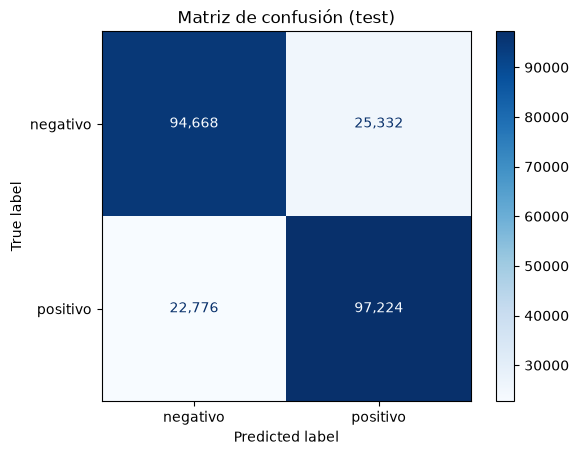

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, log_loss

y_true = test["label"].to_numpy()
y_prob = modelo.predict_proba(textos_test)[:, 1]
y_pred = modelo.predict(textos_test)

test_loss = log_loss(y_true, y_prob)
test_acc = modelo.score(textos_test, y_true)
test_auc = roc_auc_score(y_true, y_prob)

print(f"Test  -> loss: {test_loss:.4f} | accuracy: {test_acc:.4f} | AUC: {test_auc:.4f}")
print(classification_report(y_true, y_pred, target_names=["negativo", "positivo"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=["negativo", "positivo"]).plot(cmap="Blues", values_format=",")
plt.title("Matriz de confusión (test)")
plt.show()

### Análisis de errores

Vemos los tuits en los que el modelo se equivoca con más seguridad. Suele tratarse de ironía, de etiquetas ruidosas (recordemos que la etiqueta viene del emoticono, no de una persona) o de frases cuyo sentimiento depende de contexto externo.

In [20]:
errores = test.assign(prob=y_prob, pred=y_pred)
errores = errores[errores["pred"] != errores["label"]]
errores = errores.assign(confianza=(errores["prob"] - 0.5).abs()).sort_values("confianza", ascending=False)

pd.set_option("display.max_colwidth", 120)
print(errores[["text", "label", "prob"]].head(10))

                                                                                                                            text  \
1503995  Don't u hate tht wen you cry, you're too lazy to wipe em away so tears like drip down it face and down ur neck? Sry ...   
1475813  my mom was here today  it's not allowed 2 leave the hospital but my dad picked her up  But now she's back there &amp...   
1518550                     @DreamMyWishes awwww poor thing!! If you're missing cera you must be feeling awful. Feel better boo    
1572530        everyone thats sad, depressed, unhappy, sad ): cheer upp please! its the last week of school. be happy everyone!    
1096505  I don't know what I could do 2day. Ergh! I'm so bored  Don't wanna stay at home all day. But I HATE the weather 2day...   
1236350  @justex07  I love it. My stupid throat hurts so badly; I hope I'm not sick b/c then everyone I went sailing w/will p...   
1045335   @thatrosie so jealous i really wanted to watch it!! was it sad did

# Predicción sobre frases nuevas

Para clasificar texto nuevo aplicamos exactamente el mismo pipeline: `preprocess` → unir tokens → `vectorizator` → modelo.

In [29]:
def predecir(textos):
    tokens_procesados = [" ".join(preprocess(t)) for t in textos]
    probs = modelo.predict_proba(tokens_procesados)[:, 1]
    preds = modelo.predict(tokens_procesados)
    
    for texto, p, pred in zip(textos, probs, preds):
        etiqueta = "positivo" if pred == 1 else "negativo"
        print(f"{p:.3f}  {etiqueta:<8}  {texto}")

predecir([
    "I love love movies",
    "I can't believe how bad this day was :(",
    "just got my new phone, sooo happy!!!",
    "I don't hate it, it's actually not bad",
    "worst customer service ever, never again",
    "@john thanks for the help yesterday <3",
    "hello",
    "bye",
    ":(",
    ":)",
    ":) :(",
    ":( :)",
    "<3",
    "fuck",
    "heheh"
])

0.912  positivo  I love love movies
0.001  negativo  I can't believe how bad this day was :(
0.807  positivo  just got my new phone, sooo happy!!!
0.017  negativo  I don't hate it, it's actually not bad
0.057  negativo  worst customer service ever, never again
0.868  positivo  @john thanks for the help yesterday <3
0.828  positivo  hello
0.459  negativo  bye
0.025  negativo  :(
0.722  positivo  :)
0.047  negativo  :) :(
0.047  negativo  :( :)
0.558  positivo  <3
0.442  negativo  fuck
0.897  positivo  heheh
